# Image Compression: Decomposicao de Valores Singulares

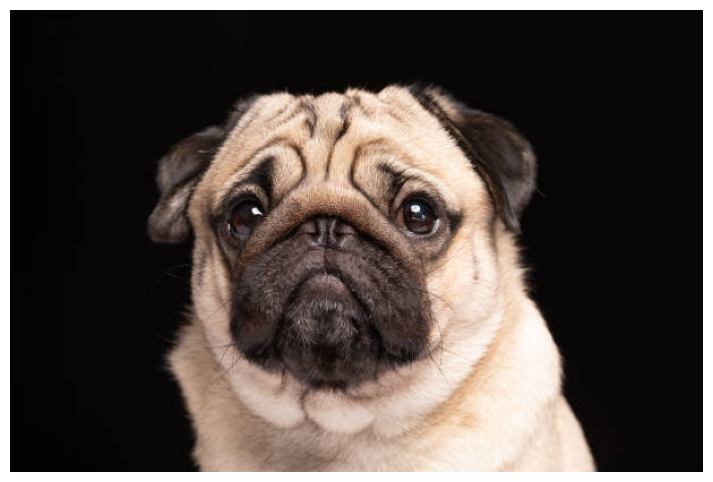

In [2]:
from matplotlib.image import imread
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams['figure.figsize'] = [12,6]

A = imread('../images/image_compression/dog.jpg')

plt.imshow(A)
plt.axis('off')
plt.show()

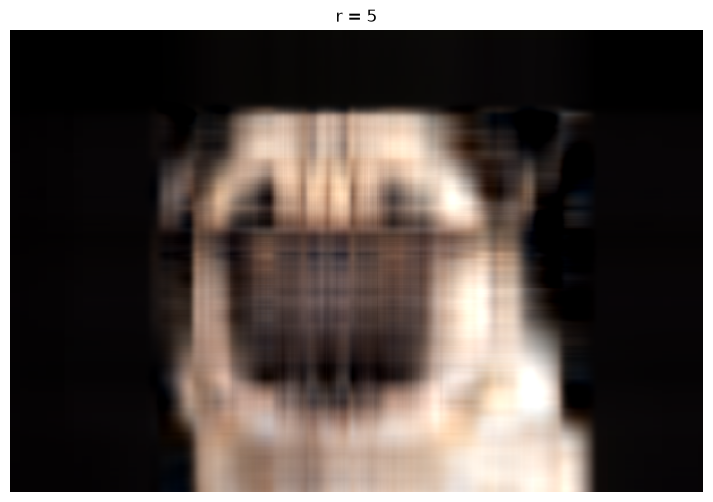

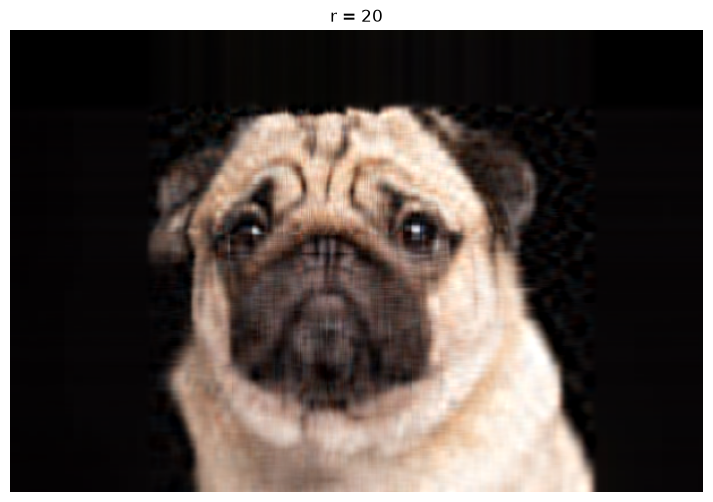

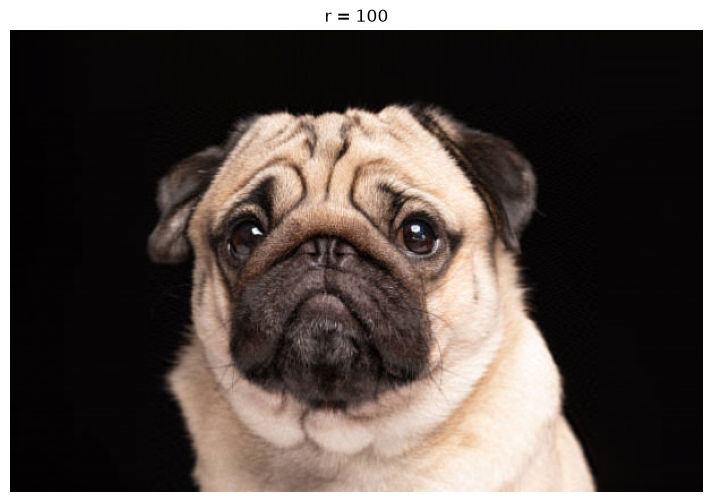

In [3]:
svds = [
    np.linalg.svd(A[:, :, canal], full_matrices=False)
    for canal in range(3)
]

for r in (5, 20, 100):
    canais = []

    for U, S, VT in svds:
        canal_comprimido = U[:, :r] @ np.diag(S[:r]) @ VT[:r, :]
        canais.append(canal_comprimido)

    Xapprox = np.stack(canais, axis=2)
    Xapprox = np.clip(Xapprox, 0, 255).astype(np.uint8)

    plt.figure()
    plt.imshow(Xapprox)
    plt.axis('off')
    plt.title(f'r = {r}')
    plt.show()

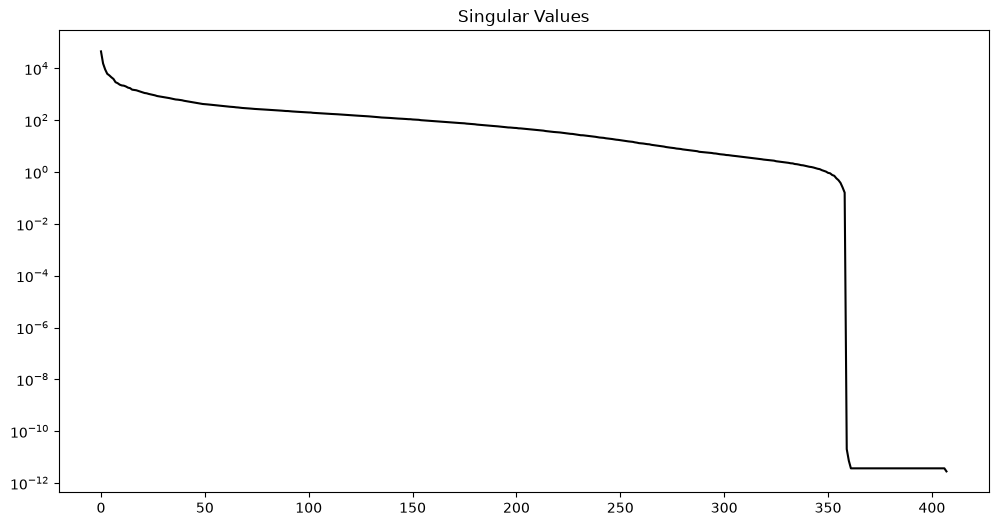

In [10]:
S_medio = np.mean([resultado[1] for resultado in svds], axis=0)

plt.figure()
plt.semilogy(S_medio, color='black')
plt.title('Singular Values')
plt.show()

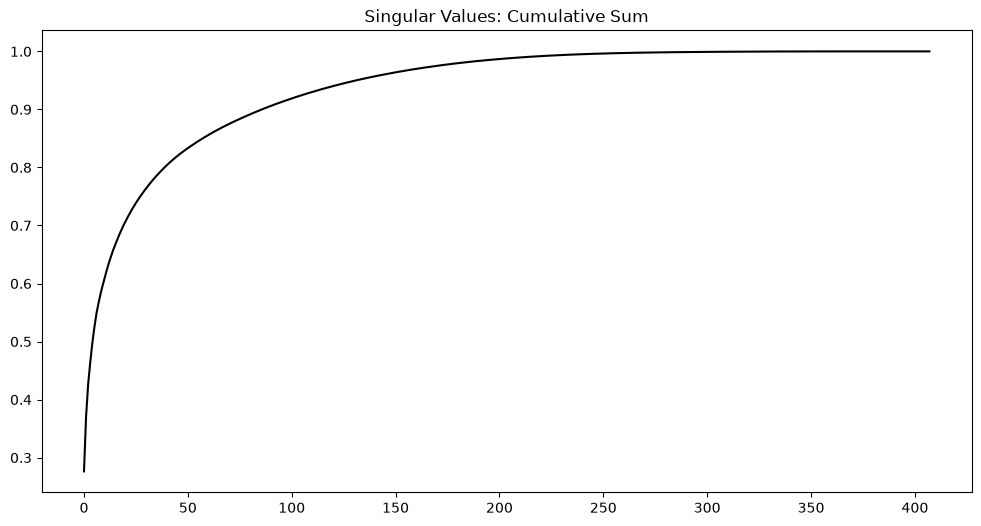

In [9]:
plt.figure()
plt.plot(
    np.cumsum(S_medio) / np.sum(S_medio),
    color='black'
)
plt.title('Singular Values: Cumulative Sum')
plt.show()